In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
import sklearn.preprocessing
from scipy import stats

In [2]:
retail_data = fetch_ucirepo(id=352)

In [3]:
df = retail_data.data.original.copy()

In [4]:
df.shape

(541909, 8)

In [5]:
df.sample(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
408114,571931,23171,REGENCY TEA PLATE GREEN,1,10/19/2011 16:59,3.29,NaN,United Kingdom
494247,578265,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,4,11/23/2011 13:28,3.75,13018.0,United Kingdom
224179,556507,23281,FOLDING BUTTERFLY MIRROR RED,12,6/13/2011 9:55,0.83,12567.0,France
513322,579546,22385,JUMBO BAG SPACEBOY DESIGN,2,11/30/2011 10:37,2.08,NaN,United Kingdom
76372,542624,20718,RED RETROSPOT SHOPPER BAG,1,1/31/2011 9:48,3.29,NaN,United Kingdom
135338,547892,22554,PLASTERS IN TIN WOODLAND ANIMALS,12,3/28/2011 10:15,1.65,12669.0,France
376351,569523,23533,WALL ART GARDEN HAVEN,1,10/4/2011 14:41,5.95,16033.0,United Kingdom
37914,539488,22037,ROBOT BIRTHDAY CARD,12,12/20/2010 9:37,0.42,12377.0,Switzerland
644,536415,22594,CHRISTMAS GINGHAM TREE,5,12/1/2010 11:57,0.85,12838.0,United Kingdom
141899,548522,85199S,SMALL HANGING IVORY/RED WOOD BIRD,2,3/31/2011 16:43,0.83,NaN,United Kingdom


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [7]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.isna().mean()*100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [9]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df = df.drop_duplicates()

In [11]:
stock_to_desc = (
    df.dropna(subset=['Description'])
    .groupby('StockCode')['Description']
    .first()
)

df['Description'] = df['Description'].fillna(df['StockCode'].map(stock_to_desc))

df['Description'] = df['Description'].fillna('Unknown')

print("Remaining nulls in Description:", df['Description'].isna().sum())


Remaining nulls in Description: 0


In [12]:
df.shape

(536641, 8)

In [13]:
df.columns.tolist()

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [14]:
df = df[(df['Quantity']>0) & (df['UnitPrice']>0)].copy()

In [15]:
df.shape

(524878, 8)

In [16]:
df = df[~df["InvoiceNo"].astype("str").str.startswith("C")]

In [17]:
df.shape

(524878, 8)

In [18]:
df['Country'] = df['Country'].astype('str').str.strip().astype('category')
df['Quantity'] = pd.to_numeric(df['Quantity'], errors = 'coerce')
df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors = 'coerce')

In [19]:
df['CustomerID'] = df['CustomerID'].astype('Int64').astype('str')

In [20]:
df.dtypes

InvoiceNo           str
StockCode           str
Description         str
Quantity          int64
InvoiceDate         str
UnitPrice       float64
CustomerID          str
Country        category
dtype: object

In [21]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors = 'coerce')

In [22]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,524878.0,10.6166,1.0,1.0,4.0,11.0,80995.0,156.280031
InvoiceDate,524878,2011-07-04 15:30:16.317049,2010-12-01 08:26:00,2011-03-28 12:13:00,2011-07-20 11:22:00,2011-10-19 11:41:00,2011-12-09 12:50:00,NaN
UnitPrice,524878.0,3.922573,0.001,1.25,2.08,4.13,13541.33,36.093028


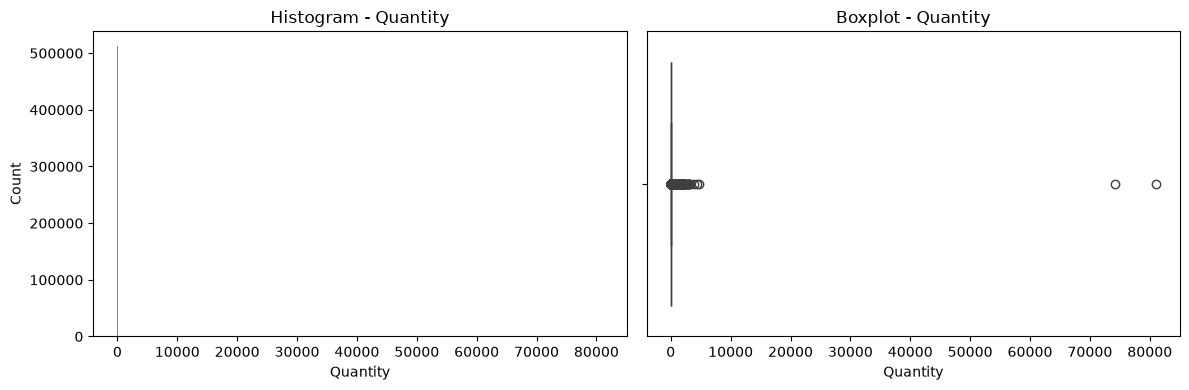

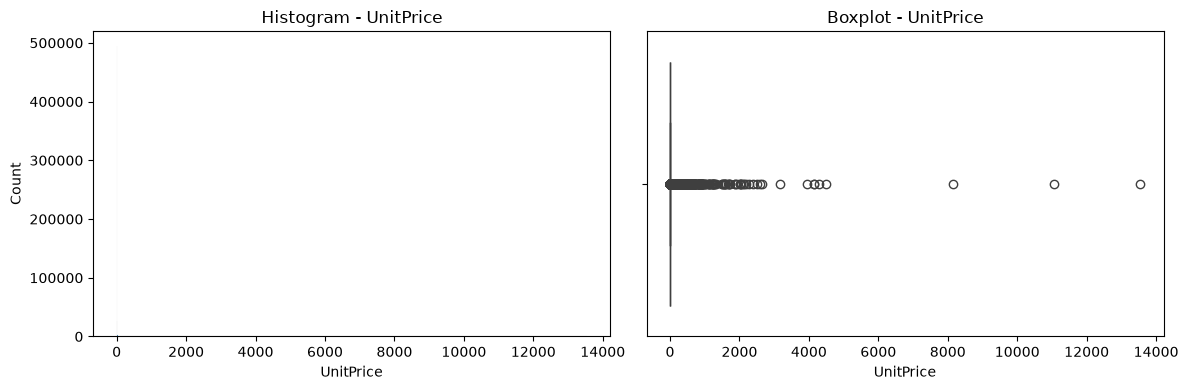

In [23]:
continuous_cols = ['Quantity', 'UnitPrice']
for col in continuous_cols:
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    sns.histplot(df[col], ax = ax[0])
    ax[0].set_title(f'Histogram - {col}')
    sns.boxplot(x = df[col], ax = ax[1])
    ax[1].set_title(f'Boxplot - {col}')
    plt.tight_layout()
    plt.show()

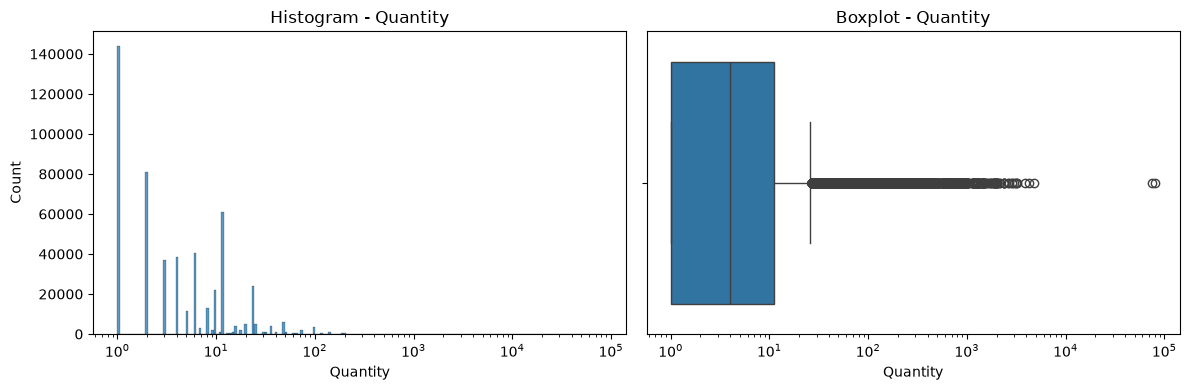

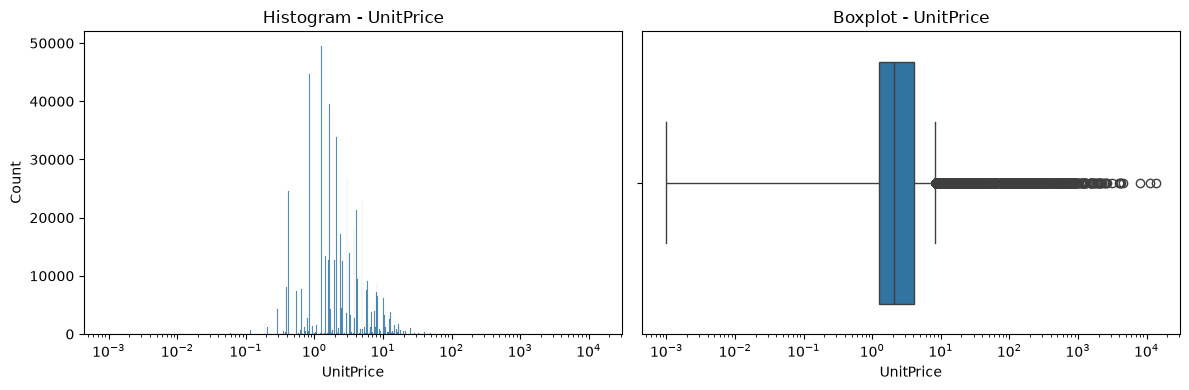

In [24]:
continuous_cols = ['Quantity', 'UnitPrice']
for col in continuous_cols:
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    sns.histplot(df[col], log_scale = True, ax = ax[0])
    ax[0].set_title(f'Histogram - {col}')
    sns.boxplot(x = df[col], ax = ax[1])
    ax[1].set_xscale('log')
    ax[1].set_title(f'Boxplot - {col}')
    plt.tight_layout()
    plt.show() 

In [25]:
cols = ['Quantity', 'UnitPrice']

for col in cols:
    lower_limit = df[col].quantile(0.01)
    upper_limit = df[col].quantile(0.99)
    df[col] = df[col].clip(lower=lower_limit, upper=upper_limit)
print(df[cols].describe())


            Quantity      UnitPrice
count  524878.000000  524878.000000
mean        8.839208       3.239734
std        15.321080       3.231542
min         1.000000       0.290000
25%         1.000000       1.250000
50%         4.000000       2.080000
75%        11.000000       4.130000
max       100.000000      16.980000


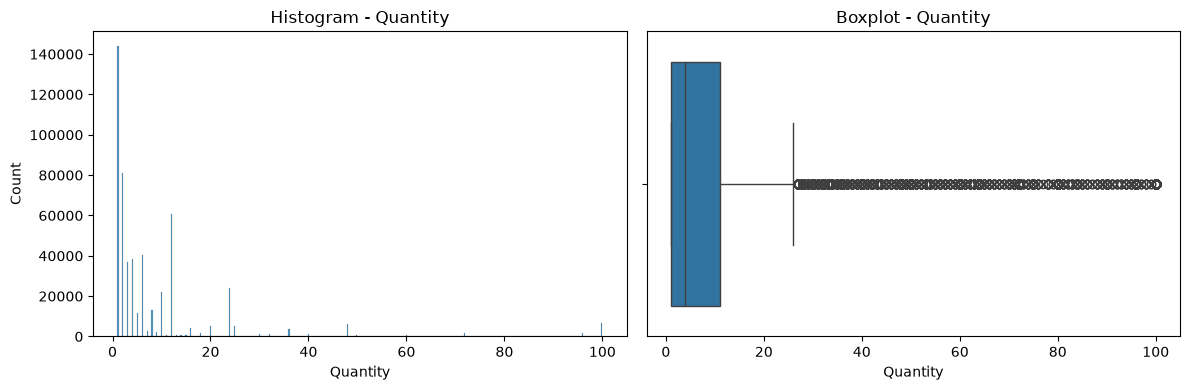

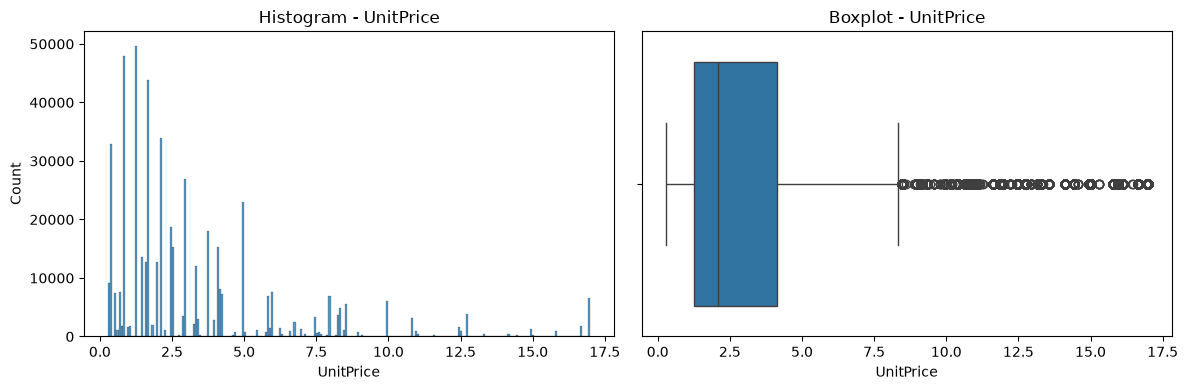

In [26]:
continuous_cols = ['Quantity', 'UnitPrice']
for col in continuous_cols:
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    sns.histplot(df[col], ax = ax[0])
    ax[0].set_title(f'Histogram - {col}')
    sns.boxplot(x = df[col], ax = ax[1])
    ax[1].set_title(f'Boxplot - {col}')
    plt.tight_layout()
    plt.show()

In [27]:
df['Country'].value_counts()

Country
United Kingdom          479985
Germany                   9025
France                    8392
EIRE                      7879
Spain                     2479
Netherlands               2359
Belgium                   2031
Switzerland               1958
Portugal                  1492
Australia                 1181
Norway                    1071
Italy                      758
Channel Islands            747
Finland                    685
Cyprus                     603
Sweden                     450
Unspecified                442
Austria                    398
Denmark                    380
Poland                     330
Japan                      321
Israel                     292
Hong Kong                  280
Singapore                  222
Iceland                    182
USA                        179
Canada                     151
Greece                     145
Malta                      112
United Arab Emirates        68
European Community          60
RSA                         57


In [28]:
country_pct = df['Country'].value_counts(normalize=True) * 100
cumulative_pct = country_pct.cumsum()
print(cumulative_pct[cumulative_pct <= 99])

Country
United Kingdom     91.446965
Germany            93.166412
France             94.765260
EIRE               96.266370
Spain              96.738671
Netherlands        97.188108
Belgium            97.575056
Switzerland        97.948095
Portugal           98.232351
Australia          98.457356
Norway             98.661403
Italy              98.805818
Channel Islands    98.948137
Name: proportion, dtype: float64


In [29]:
top_countries = cumulative_pct[cumulative_pct <= 99].index
df = df[df['Country'].isin(top_countries)]

In [30]:
df.shape

(519357, 8)

In [31]:
df['StockCode'].value_counts()

StockCode
85123A    2241
85099B    2096
22423     1973
47566     1684
20725     1572
          ... 
85179a       1
23617        1
90214U       1
47591b       1
23843        1
Name: count, Length: 3921, dtype: int64

In [32]:
df = df[df['StockCode'].astype(str).str.match(r'^\d{5}')]

In [33]:
stock_codes = df['StockCode'].value_counts()
print(stock_codes.describe())

count    3899.000000
mean      132.624263
std       193.824722
min         1.000000
25%        16.000000
50%        65.000000
75%       165.000000
max      2241.000000
Name: count, dtype: float64


In [34]:
stock_count = df['StockCode'].value_counts(normalize = True)*100
cumulative_pct = stock_count.cumsum()

In [35]:
print()

In [36]:
top_stock_list = cumulative_pct[cumulative_pct<=99].index

In [37]:
df = df[df['StockCode'].isin(top_stock_list)]

In [38]:
df.shape

(511921, 8)

In [39]:
df['Is_UK'] = df['Country'].str.strip() == 'United Kingdom'

In [40]:
df = df.drop(columns = "Country")

In [41]:
df['Quantity'] = np.log1p(df['Quantity'])
df['UnitPrice'] = np.log1p(df['UnitPrice'])

In [42]:
scaler = sklearn.preprocessing.StandardScaler()

In [43]:
df[['Quantity', 'UnitPrice']] = scaler.fit_transform(df[['Quantity', 'UnitPrice']])

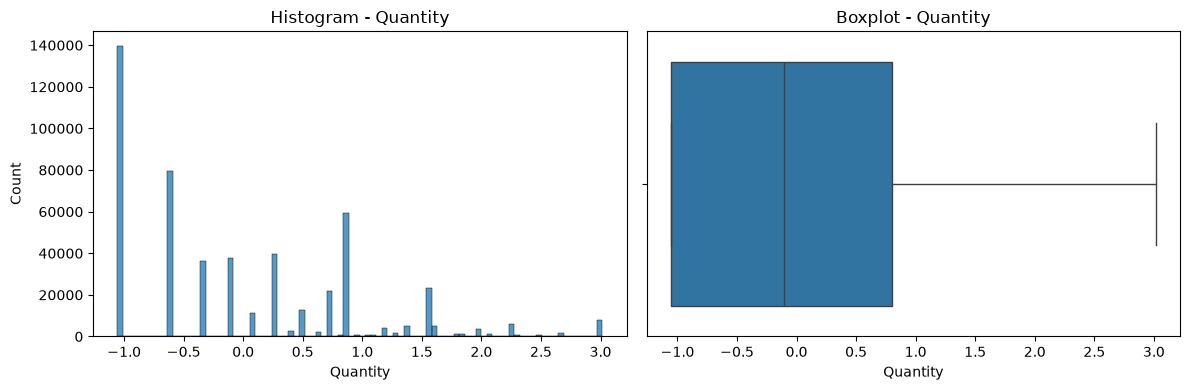

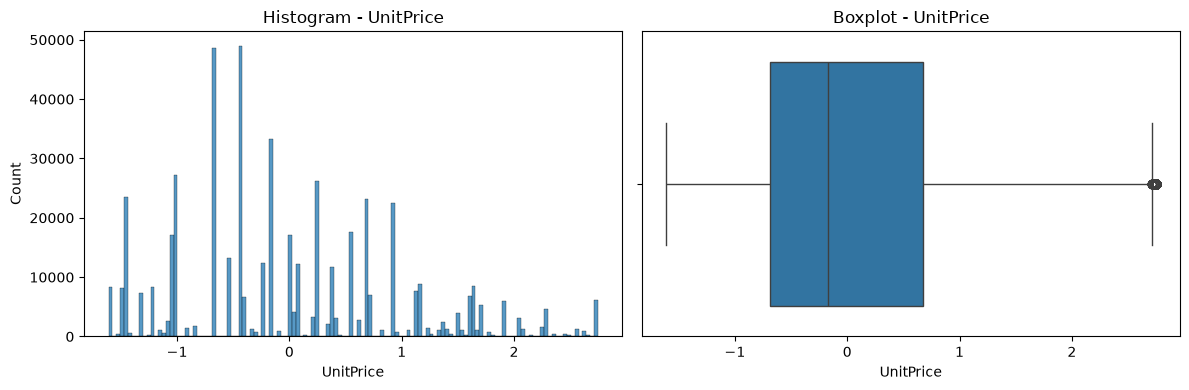

In [44]:
continuous_cols = ['Quantity', 'UnitPrice']
for col in continuous_cols:
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    sns.histplot(df[col], ax = ax[0])
    ax[0].set_title(f'Histogram - {col}')
    sns.boxplot(x = df[col], ax = ax[1])
    ax[1].set_title(f'Boxplot - {col}')
    plt.tight_layout()
    plt.show()

In [45]:
df.info()

<class 'pandas.DataFrame'>
Index: 511921 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    511921 non-null  str           
 1   StockCode    511921 non-null  str           
 2   Description  511921 non-null  str           
 3   Quantity     511921 non-null  float64       
 4   InvoiceDate  511921 non-null  datetime64[us]
 5   UnitPrice    511921 non-null  float64       
 6   CustomerID   383019 non-null  str           
 7   Is_UK        511921 non-null  bool          
dtypes: bool(1), datetime64[us](1), float64(2), str(4)
memory usage: 52.3 MB


In [46]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

In [47]:
df['InvoiceHour'] = df['InvoiceDate'].dt.hour
df['InvoiceDayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

In [48]:
quantity_bins = [0,1,5,12,100]
quantity_labels = ['Single Item', 'Small Pack (2-5)', 'Standard Pack (6-12)', 'Bulk (>12)']
df['OrderSIze'] = pd.cut(
    df['Quantity'],
    bins = quantity_bins,
    labels = quantity_labels
)

In [49]:
df['PriceTier'] = pd.qcut(
    df['UnitPrice'],
    q=4,
    labels = ['Budget', 'Standard', 'Mid-Range', 'Premium']
)

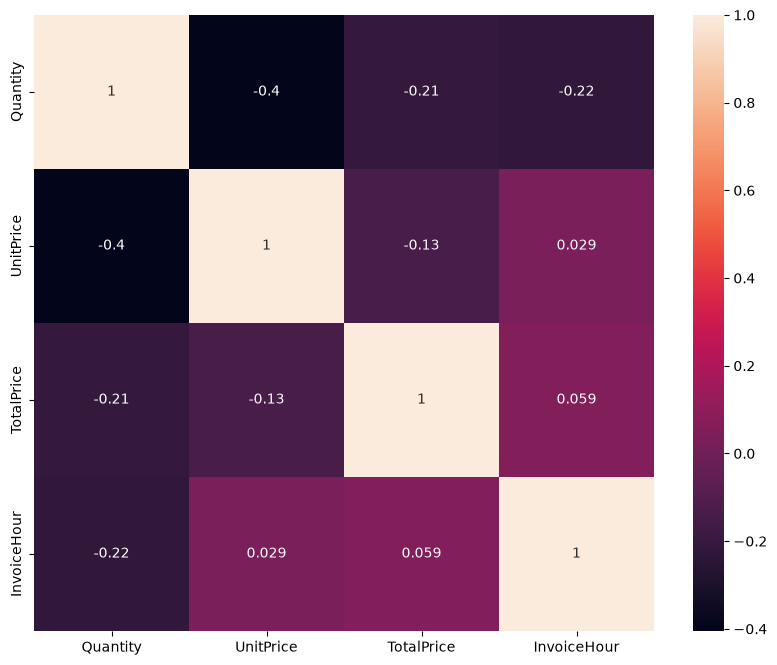

In [52]:
num_cols = ['Quantity', 'UnitPrice', 'TotalPrice', 'InvoiceHour']
plt.figure(figsize=(10,8))
corr_matrix = df[num_cols].corr(method = 'spearman')
sns.heatmap(corr_matrix, annot=True)
plt.show()